# Random Forest: airline satisfaction

Train the original 100-tree forest and compare it with a forest selected by exhaustive grid search. Reserve 20% of the labeled training data for the holdout comparison. Use three stratified folds within the remaining 80% to select settings by mean accuracy.

In [1]:
from pathlib import Path
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, precision_score, recall_score,
)
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split

# Find the project from the notebooks directory or the project root.
cwd = Path.cwd()
project_root = next(path for path in (cwd, *cwd.parents) if (path / "src/preprocessing.py").is_file())
sys.path.insert(0, str(project_root))

from src.preprocessing import rating_cols, run_full_preprocessing

In [2]:
def encode_labels(values):
    labels = {
        "satisfied": 1, "true": 1, "1": 1,
        "neutral or dissatisfied": 0, "false": 0, "0": 0,
    }
    encoded = values.astype(str).str.strip().str.lower().map(labels)
    if encoded.isna().any():
        unexpected = values[encoded.isna()].unique()
        raise ValueError(f"Unexpected satisfaction labels: {unexpected}")
    return encoded.astype(int)


df = pd.read_csv(project_root / "data/train.csv")
# Exclude the target, passenger ID, and any serialized CSV index.
X = df.drop(columns=["satisfaction", "id"]).filter(regex=r"^(?!Unnamed:)")
y = encode_labels(df["satisfaction"])

seed = 42
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=seed
)
print(f"scikit-learn {sklearn.__version__} | training {len(X_train):,} | holdout {len(X_val):,}")
print(pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Holdout (%)": y_val.value_counts(normalize=True) * 100,
}).round(2))

scikit-learn 1.7.2 | training 83,123 | holdout 20,781
              Train (%)  Holdout (%)
satisfaction                        
0                 56.67        56.67
1                 43.33        43.33


## Preprocess each split

Fit arrival-delay and service-rating imputation, categorical encoding, and scaling on the training rows of each split. Preserve zero-rating indicators and reuse the project's engineered features. Within each fold, all grid candidates use the same preprocessed inputs.

In [3]:
def prepare(training, evaluation):
    arrival_col = "Arrival Delay in Minutes"
    arrival_median = training[arrival_col].median()

    def clean(frame):
        frame = frame.copy()
        frame[arrival_col] = frame[arrival_col].fillna(arrival_median)
        for col in rating_cols:
            frame[col + "_not_rated"] = frame[col].eq(0).astype(int)
            frame[col] = frame[col].replace(0, np.nan)
        return frame

    train_proc, eval_proc, _, _ = run_full_preprocessing(clean(training), clean(evaluation))
    return train_proc, eval_proc

## Exhaustive grid search

Evaluate all 48 combinations of depth, minimum leaf size, and features per split. Each configuration uses 100 trees and runs on the same three stratified folds. Select the highest mean fold accuracy, then use the reserved holdout for the comparison.

In [4]:
baseline_params = dict(max_depth=None, min_samples_leaf=1, max_features="sqrt")
grid = ParameterGrid({
    "max_depth": [12, 20, 30, None],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", 0.3, 0.5],
})


def make_forest(params):
    return RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1, **params)


cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
n_folds = cv.get_n_splits()
scores = np.empty((len(grid), n_folds))
search_started = perf_counter()
print(f"Running {len(grid)} combinations × {n_folds} folds ({len(grid) * n_folds} fits).")
for fold, (fit_idx, score_idx) in enumerate(cv.split(X_train, y_train)):
    fit_X, score_X = prepare(X_train.iloc[fit_idx], X_train.iloc[score_idx])
    fit_y, score_y = y_train.iloc[fit_idx], y_train.iloc[score_idx]
    for index, params in enumerate(grid):
        candidate = make_forest(params).fit(fit_X, fit_y)
        scores[index, fold] = candidate.score(score_X, score_y)
        if (index + 1) % 12 == 0:
            print(f"Fold {fold + 1}/{n_folds}: scored {index + 1}/{len(grid)} candidates")

mean_accuracy = scores.mean(axis=1)
best_index = int(mean_accuracy.argmax())
best_params = grid[best_index]
baseline_index = list(grid).index(baseline_params)
grid_results = pd.DataFrame(list(grid), dtype=object).assign(
    mean_accuracy=mean_accuracy, fold_sd=scores.std(axis=1)
).sort_values("mean_accuracy", ascending=False, kind="stable").reset_index(drop=True)

print(f"Grid search took {perf_counter() - search_started:.1f} seconds.")
print(grid_results.to_string(index=False, float_format=lambda value: f"{value:.4%}"))
print(f"Baseline mean CV accuracy: {mean_accuracy[baseline_index]:.4%}")
print(f"Best mean CV accuracy: {mean_accuracy[best_index]:.4%}")
print(f"Best parameters: {best_params}")

Running 48 combinations × 3 folds (144 fits).
Fold 1/3: scored 12/48 candidates
Fold 1/3: scored 24/48 candidates
Fold 1/3: scored 36/48 candidates
Fold 1/3: scored 48/48 candidates
Fold 2/3: scored 12/48 candidates
Fold 2/3: scored 24/48 candidates
Fold 2/3: scored 36/48 candidates
Fold 2/3: scored 48/48 candidates
Fold 3/3: scored 12/48 candidates
Fold 3/3: scored 24/48 candidates
Fold 3/3: scored 36/48 candidates
Fold 3/3: scored 48/48 candidates
Grid search took 296.4 seconds.
max_depth max_features min_samples_leaf  mean_accuracy  fold_sd
       20     50.0000%                1       96.1298%  0.1308%
     None     50.0000%                1       96.1166%  0.1540%
       30     50.0000%                1       96.0709%  0.1694%
       20     30.0000%                1       96.0552%  0.1755%
       30     30.0000%                1       96.0528%  0.1685%
       30     50.0000%                4       96.0480%  0.1704%
       20     50.0000%                2       96.0408%  0.1739%
  

## Evaluation metrics

The positive class is **satisfied (1)**; the negative class is **neutral or dissatisfied (0)**.

- **TP:** actually satisfied and predicted satisfied.
- **TN:** actually negative and predicted negative.
- **FP:** actually negative but predicted satisfied.
- **FN:** actually satisfied but predicted negative.

**Accuracy** measures the fraction of all predictions that are correct:

$$
\mathrm{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

**Precision** measures how many passengers predicted satisfied are actually satisfied:

$$
\mathrm{Precision} = \frac{TP}{TP + FP}
$$

**Recall** measures how many actually satisfied passengers are predicted satisfied:

$$
\mathrm{Recall} = \frac{TP}{TP + FN}
$$


Original baseline on the 20% holdout
Accuracy: 95.9578%
Precision (satisfied): 96.5030%
Recall (satisfied): 94.0811%
Confusion matrix (rows: actual, columns: predicted, class order: 0, 1)
[[11469   307]
 [  533  8472]]

Grid search on the 20% holdout
Accuracy: 96.2562%
Precision (satisfied): 96.9096%
Recall (satisfied): 94.3698%
Confusion matrix (rows: actual, columns: predicted, class order: 0, 1)
[[11505   271]
 [  507  8498]]



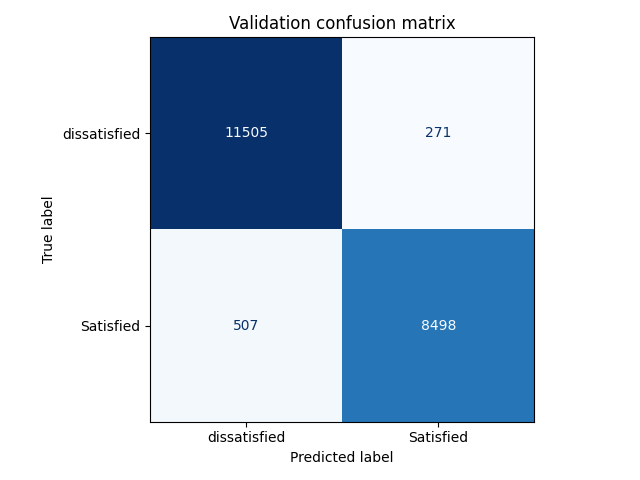

In [5]:
X_train_proc, X_val_proc = prepare(X_train, X_val)

for label, params in [("Original baseline", baseline_params), ("Grid search", best_params)]:
    model = make_forest(params).fit(X_train_proc, y_train)
    predictions = model.predict(X_val_proc)
    print(f"{label} on the 20% holdout")
    print(f"Accuracy: {accuracy_score(y_val, predictions):.4%}")
    print(f"Precision (satisfied): {precision_score(y_val, predictions, zero_division=0):.4%}")
    print(f"Recall (satisfied): {recall_score(y_val, predictions, zero_division=0):.4%}")
    print("Confusion matrix (rows: actual, columns: predicted, class order: 0, 1)")
    print(confusion_matrix(y_val, predictions, labels=[0, 1]))
    print()


# Plot the selected model's holdout predictions in the original notebook's style.
ConfusionMatrixDisplay.from_predictions(
    y_val, predictions,
    labels=[0, 1],
    display_labels=["dissatisfied", "Satisfied"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
plt.title("Validation confusion matrix")
plt.tight_layout()
plt.show()


## Refit and evaluate the separate test data

Train the selected configuration on all labeled training rows. If the test file has labels, report its accuracy. For an unlabeled competition file, export satisfaction probabilities in test ID order.

In [6]:
test_df = pd.read_csv(project_root / "data/test.csv")
X_full_proc, X_test_proc = prepare(X, test_df[X.columns])
final_model = make_forest(best_params).fit(X_full_proc, y)

if "satisfaction" in test_df:
    y_test = encode_labels(test_df["satisfaction"])
    print(f"Separate test accuracy ({len(test_df):,} rows): {final_model.score(X_test_proc, y_test):.4%}")
else:
    template_path = project_root / "data/sample_submission.csv"
    submission = pd.read_csv(template_path) if template_path.is_file() else test_df[["id"]].copy()
    if not submission["id"].equals(test_df["id"]):
        raise ValueError("Test IDs do not match the submission template.")
    positive_class = list(final_model.classes_).index(1)
    submission["satisfaction"] = final_model.predict_proba(X_test_proc)[:, positive_class]
    submission_path = project_root / "submissions/random_forest_grid.csv"
    submission_path.parent.mkdir(exist_ok=True)
    submission.to_csv(submission_path, index=False)
    print(f"Saved {len(submission):,} predictions to {submission_path}")

Separate test accuracy (25,976 rows): 96.3274%


## Original Kaggle submission

This screenshot shows the original 100-tree notebook's Kaggle score on the competition dataset. The grid search above reports scores on the data files supplied to this notebook.

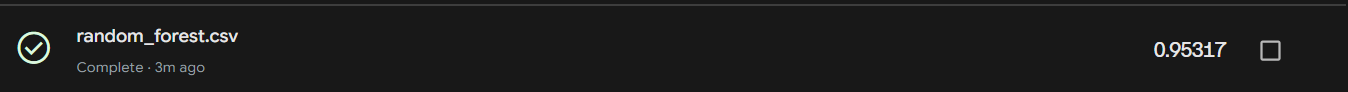